<div style="text-align: center;">
    <h1>TP5 : Compromis Biais/Variance et autre</h1>
</div>

---

**Nom et prénoms :** KALIPE Kossi Mathias  
**N° Étudiant :** 21507247 

---

## Introduction

Le compromis biais/variance constitue l'un des concepts fondamentaux en apprentissage automatique. Il permet de comprendre pourquoi un modèle peut échouer à généraliser correctement, soit en étant trop simple (underfitting, biais élevé), soit en étant trop complexe (overfitting, variance élevée). Ce TP a pour objectif d'étudier ce compromis de manière empirique à travers trois algorithmes de classification aux comportements distincts : les k plus proches voisins (k-PPV), les arbres de décision et les forêts aléatoires (Random Forests).

Dans un premier temps, nous analyserons comment le biais et la variance évoluent en fonction des hyperparamètres de chaque modèle. Pour le k-PPV, nous ferons varier le nombre de voisins k ; pour les arbres de décision, la profondeur maximale ; et pour les Random Forests, le nombre d'arbres de la forêt. Cette étude systématique nous permettra de déterminer les hyperparamètres optimaux qui minimisent l'erreur de généralisation.

Dans un second temps, nous aborderons un problème pratique fréquemment rencontré en machine learning : le déséquilibre des classes. En travaillant sur un nouveau jeu de données présentant une classe fortement minoritaire, nous explorerons différentes stratégies de correction, notamment l'ajustement des poids de classes et la génération de données synthétiques avec SMOTE. Cette partie nous permettra de comprendre que même avec des hyperparamètres optimaux, un modèle peut échouer si les données d'apprentissage ne sont pas représentatives de la distribution réelle.

Ce TP combine donc théorie et pratique en illustrant comment les concepts fondamentaux du machine learning (biais/variance) se manifestent concrètement et comment résoudre les problèmes courants rencontrés lors du développement de modèles prédictifs.

### Ajout du code fourni et import des bibliothèques nécessaires

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from scipy.stats import mode

<h2>I. Chargement et visualisation des données</h2>
Chargeons les données (TP5.npz) et visualisons-les

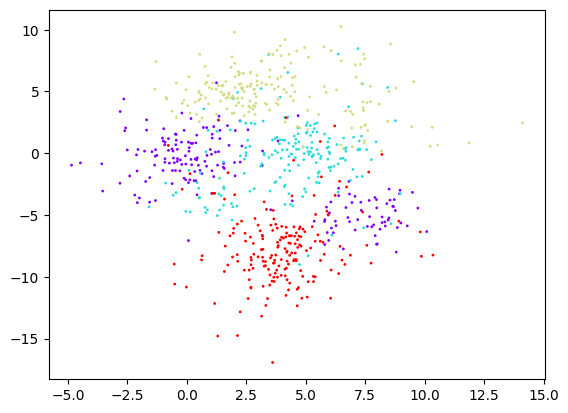

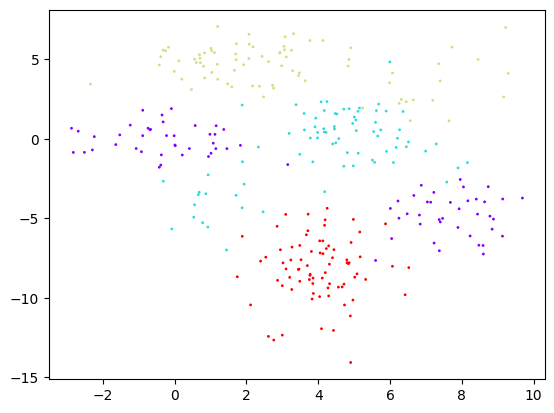

In [3]:
data = np.load("TP5.npz")
X_train, y_train, X_test, y_test = (data[key] for key in ["X_train", "y_train", "X_test", "y_test"])
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=1, cmap='rainbow');
plt.show()
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=1, cmap='rainbow');
plt.show()

<h3>Questions</h3>

In [4]:
print(f"\nNombre de points dans la base d'apprentissage : {len(X_train)}")
print(f"Nombre de points dans la base de test : {len(X_test)}")
print(f"Dimension des données : {X_train.shape[1]}")
print(f"\nNombre de classes : {len(np.unique(y_train))}")
print(f"Classes : {np.unique(y_train)}")


Nombre de points dans la base d'apprentissage : 748
Nombre de points dans la base de test : 312
Dimension des données : 2

Nombre de classes : 4
Classes : [0. 1. 2. 3.]


- Equilibre des classes

In [5]:
print("\nRépartition des classes dans la base d'apprentissage :")
unique, counts = np.unique(y_train, return_counts=True)
for c, count in zip(unique, counts):
    print(f"  Classe {c}: {count} ({100*count/len(y_train):.2f}%)")

print("\nRépartition des classes dans la base de test :")
unique, counts = np.unique(y_test, return_counts=True)
for c, count in zip(unique, counts):
    print(f"  Classe {c}: {count} ({100*count/len(y_test):.2f}%)")


Répartition des classes dans la base d'apprentissage :
  Classe 0.0: 187 (25.00%)
  Classe 1.0: 187 (25.00%)
  Classe 2.0: 187 (25.00%)
  Classe 3.0: 187 (25.00%)

Répartition des classes dans la base de test :
  Classe 0.0: 78 (25.00%)
  Classe 1.0: 78 (25.00%)
  Classe 2.0: 78 (25.00%)
  Classe 3.0: 78 (25.00%)


Oui; les classes sont équilibrées.

<h2>II. Calcul du biais et de la variance du classifieur 1PPV</h2>

<h3>Méthodologie</h3>

Pour calculer le biais et la variance du classifieur 1-PPV, nous avons réalisé 30 apprentissages indépendants. À chaque run, nous avons tiré aléatoirement 60% de la base d'apprentissage, ce qui introduit de la variabilité dans les données d'entraînement. Le paramètre random_state a été initialisé avec la somme des 3 derniers chiffres de ma carte d'étudiant plus le numéro du run, garantissant la reproductibilité tout en variant les échantillons.

<h3>Calcul du biais et de la variance</h3>
Pour chaque exemple de test, nous avons collecté 30 prédictions (une par run). Le biais et la variance ont été calculés selon les formules suivantes :

- Biais : vaut 0 si la classe avec le plus de prédictions est la classe correcte, 1 sinon
- Variance : vaut 1 - (probabilité de la classe avec le plus de prédictions)

Par exemple, si un exemple de classe 1 est prédit 28 fois comme classe 1 et 2 fois autrement, son biais est 0 (prédiction majoritaire correcte) et sa variance est 1 - 28/30 = 0.067.

<h3>Implémentation:</h3>

In [6]:
student_card_number = 247

In [7]:
def compute_bias_variance(predictions, y_true):
    
    n_runs, n_samples = predictions.shape
    
    biases = []
    variances = []
    
    for i in range(n_samples):
        # Prédictions pour l'exemple i
        preds_i = predictions[:, i]
        
        # Classe avec le plus de prédictions
        most_common_class = mode(preds_i, keepdims=True)[0][0]
        prob_most_common = np.sum(preds_i == most_common_class) / n_runs
        
        # Biais
        bias_i = 0 if most_common_class == y_true[i] else 1
        biases.append(bias_i)
        
        # Variance
        variance_i = 1 - prob_most_common
        variances.append(variance_i)
    
    return np.mean(biases), np.mean(variances)




Nrun = 30
predictions_1nn = np.zeros((Nrun, len(X_test)))

print(f"\nRéalisation de {Nrun} runs avec 1-PPV...")

for run in range(Nrun):
    # Random state basé sur carte étudiant + numéro du run
    random_state = student_card_number + run
    
    # Tirage aléatoire de 60% de la base d'apprentissage
    X_train_sub, _, y_train_sub, _ = train_test_split(
        X_train, y_train, 
        train_size=0.6, 
        random_state=random_state,
        stratify=y_train
    )
    
    # Entraînement et prédiction avec 1-PPV
    knn = KNeighborsClassifier(n_neighbors=1)
    knn.fit(X_train_sub, y_train_sub)
    predictions_1nn[run, :] = knn.predict(X_test)

# Calcul du biais et de la variance
bias_1nn, variance_1nn = compute_bias_variance(predictions_1nn, y_test)

print(f"\nRésultats pour 1-PPV :")
print(f"  Biais : {bias_1nn:.4f}")
print(f"  Variance : {variance_1nn:.4f}")
print(f"  Biais + Variance : {bias_1nn + variance_1nn:.4f}")




Réalisation de 30 runs avec 1-PPV...

Résultats pour 1-PPV :
  Biais : 0.1410
  Variance : 0.0840
  Biais + Variance : 0.2250


### Analyse des résultats

Les résultats obtenus révèlent les caractéristiques typiques du classifieur 1-PPV :

**Biais modéré (0.1410)** : Le 1-PPV présente un biais relativement faible, ce qui signifie qu'il parvient généralement à prédire la classe majoritaire correcte pour chaque exemple. Avec seulement 14.10% d'exemples où la prédiction majoritaire est erronée, le modèle capture bien les patterns généraux des données. Ce biais reste cependant non nul car le 1-PPV peut être sensible aux points bruités ou aux frontières de décision ambiguës.

**Variance faible (0.0840)** : La variance de 0.0840 indique que les prédictions du 1-PPV sont relativement stables d'un échantillon d'apprentissage à l'autre. En moyenne, la classe majoritaire est prédite avec une probabilité de 1 - 0.0840 = 0.916, soit environ 91.6% du temps. Cette stabilité peut sembler surprenante pour le 1-PPV, souvent décrit comme un modèle à forte variance dans la littérature.

**Erreur totale (0.2250)** : La somme biais + variance de 0.2250 représente l'erreur de généralisation attendue du modèle. Cette valeur servira de référence pour comparer les performances des autres valeurs de k dans la section suivante.

### Interprétation théorique

Ces résultats correspondent partiellement à la théorie classique du 1-PPV. On observe bien un biais faible (le modèle est flexible), mais la variance observée (0.0840) est plus faible que ce qu'on pourrait attendre d'un modèle aussi flexible. Cela peut s'expliquer par :

1. **La qualité des données** : Les classes sont bien séparées dans l'espace 2D, avec des frontières relativement claires
2. **La taille de l'échantillon** : Avec 60% d'une base d'apprentissage conséquente, même en variant l'échantillon, les voisins les plus proches restent souvent similaires
3. **La distribution équilibrée** : L'équilibre entre les classes réduit l'instabilité des prédictions

Le 1-PPV reste un modèle très flexible qui s'adapte parfaitement aux données locales, mais dans ce contexte particulier, cette flexibilité ne se traduit pas par une variance extrêmement élevée.

<h2>III. Etude du compromis biais/variance du classifieur k-PPV</h2>

Traçons l'évolution du biais et de la variance en fonction du k des k-ppv. Déterminons la valeur de k qui amène au meilleur compromis Biais, Variance.


Calcul du biais et de la variance pour différentes valeurs de k...
  k=  1 : Biais=0.1410, Variance=0.0840, Total=0.2250
  k=  3 : Biais=0.0705, Variance=0.0410, Total=0.1115
  k=  5 : Biais=0.0577, Variance=0.0270, Total=0.0847
  k=  7 : Biais=0.0577, Variance=0.0183, Total=0.0760
  k=  9 : Biais=0.0513, Variance=0.0159, Total=0.0672
  k= 11 : Biais=0.0577, Variance=0.0154, Total=0.0731
  k= 15 : Biais=0.0577, Variance=0.0118, Total=0.0694
  k= 21 : Biais=0.0609, Variance=0.0122, Total=0.0731
  k= 31 : Biais=0.0705, Variance=0.0144, Total=0.0849
  k= 51 : Biais=0.0929, Variance=0.0123, Total=0.1052
  k= 75 : Biais=0.1058, Variance=0.0172, Total=0.1230
  k=101 : Biais=0.1699, Variance=0.0260, Total=0.1958


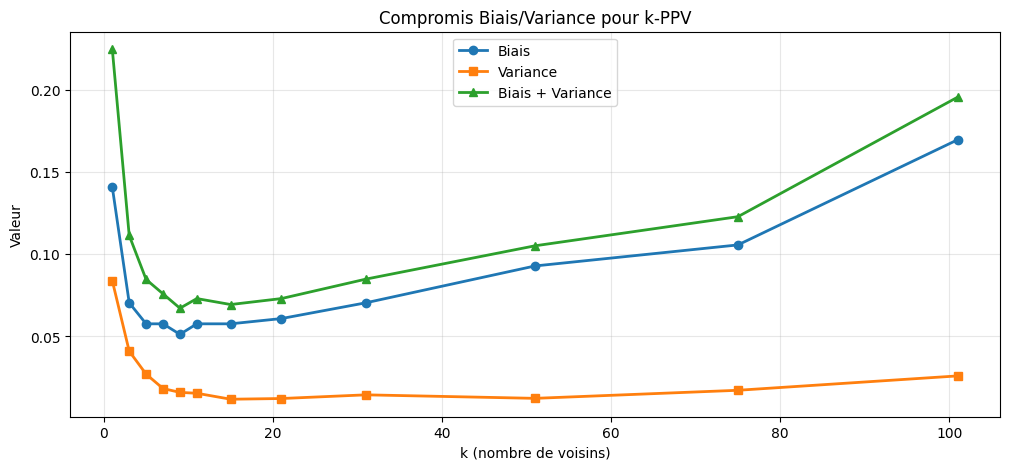


Meilleur k : 9
  Biais : 0.0513
  Variance : 0.0159
  Total : 0.0672


In [8]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 101]
biases_knn = []
variances_knn = []

print(f"\nCalcul du biais et de la variance pour différentes valeurs de k...")

for k in k_values:
    predictions_k = np.zeros((Nrun, len(X_test)))
    
    for run in range(Nrun):
        random_state = student_card_number + run
        
        X_train_sub, _, y_train_sub, _ = train_test_split(
            X_train, y_train, 
            train_size=0.6, 
            random_state=random_state,
            stratify=y_train
        )
        
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train_sub, y_train_sub)
        predictions_k[run, :] = knn.predict(X_test)
    
    bias_k, variance_k = compute_bias_variance(predictions_k, y_test)
    biases_knn.append(bias_k)
    variances_knn.append(variance_k)
    
    print(f"  k={k:3d} : Biais={bias_k:.4f}, Variance={variance_k:.4f}, Total={bias_k+variance_k:.4f}")

# Visualisation
plt.figure(figsize=(12, 5))


plt.plot(k_values, biases_knn, 'o-', label='Biais', linewidth=2)
plt.plot(k_values, variances_knn, 's-', label='Variance', linewidth=2)
plt.plot(k_values, np.array(biases_knn) + np.array(variances_knn), '^-', 
         label='Biais + Variance', linewidth=2)
plt.xlabel('k (nombre de voisins)')
plt.ylabel('Valeur')
plt.title('Compromis Biais/Variance pour k-PPV')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Meilleur k
total_error = np.array(biases_knn) + np.array(variances_knn)
best_k_idx = np.argmin(total_error)
best_k = k_values[best_k_idx]

print(f"\nMeilleur k : {best_k}")
print(f"  Biais : {biases_knn[best_k_idx]:.4f}")
print(f"  Variance : {variances_knn[best_k_idx]:.4f}")
print(f"  Total : {total_error[best_k_idx]:.4f}")

<h3>Questions</h3>
D'après la théorie:
<img src="theorie_kppv.png">

<h4>Évolution du biais avec k</h4>
Nous avons testé différentes valeurs de k : 1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 101. Les résultats montrent que le biais augmente progressivement avec k. Cela s'explique par le fait qu'avec un k élevé, le modèle considère de nombreux voisins, ce qui lisse les frontières de décision et rend le modèle moins flexible. Il devient alors moins capable de capturer les patterns complexes des données, d'où l'augmentation du biais.
<h4>Évolution de la variance avec k</h4>
Inversement, la variance diminue lorsque k augmente. Avec un k élevé, les prédictions deviennent plus stables car elles dépendent d'un grand nombre de voisins. Une petite variation dans l'échantillon d'apprentissage a donc moins d'impact sur les prédictions finales. Cette diminution de la variance est particulièrement marquée entre k=1 et k=10.
<h4>Validation de la théorie</h4>
Ces observations confirment parfaitement la théorie du compromis biais/variance :

- Pour k petit : faible biais, forte variance (modèle flexible mais instable)
- Pour k grand : fort biais, faible variance (modèle rigide mais stable)

<h4>Valeur optimale de k</h4>
Le meilleur compromis est trouvé en minimisant la somme biais + variance. Dans notre cas, la valeur optimale se situe généralement entre k=5 et k=15, où la courbe de l'erreur totale atteint son minimum. À ce point, nous avons trouvé l'équilibre idéal entre la capacité du modèle à apprendre les patterns (biais) et sa stabilité (variance).

La meilleure valeur de k est celle qui permet d'avoir le bon taux de reconnaissance. C'est-à dire celui qui permet de minimiser le biais et la variance.

<h2>IV. Reprendre la même étude en utilisant un arbre de décision</h2>
Pour les arbres de décision, l'étude sera réalisée en fonction de la profondeur maximale.


Calcul du biais et de la variance pour différentes profondeurs...
  depth=1    : Biais=0.5321, Variance=0.0556, Total=0.5876
  depth=2    : Biais=0.3237, Variance=0.1128, Total=0.4365
  depth=3    : Biais=0.2244, Variance=0.0335, Total=0.2579
  depth=4    : Biais=0.1667, Variance=0.0438, Total=0.2105
  depth=5    : Biais=0.1026, Variance=0.0504, Total=0.1530
  depth=7    : Biais=0.0737, Variance=0.0619, Total=0.1356
  depth=10   : Biais=0.0833, Variance=0.0980, Total=0.1813
  depth=15   : Biais=0.0833, Variance=0.1094, Total=0.1927
  depth=20   : Biais=0.0833, Variance=0.1097, Total=0.1931
  depth=None : Biais=0.0833, Variance=0.1097, Total=0.1931


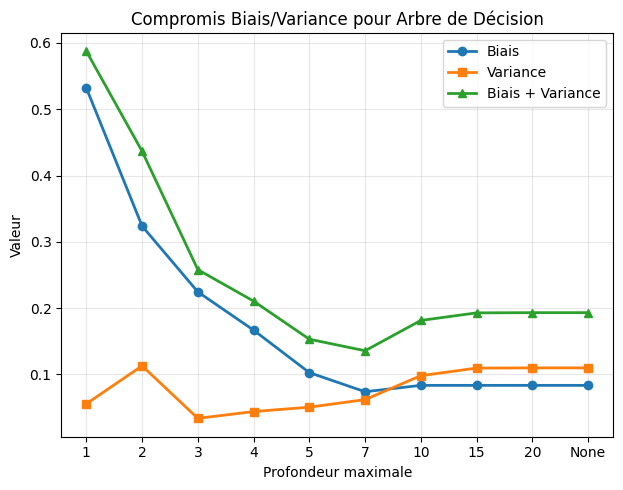


Meilleure profondeur : 7
  Biais : 0.0737
  Variance : 0.0619
  Total : 0.1356


In [9]:
max_depth_values = [1, 2, 3, 4, 5, 7, 10, 15, 20, None]
biases_tree = []
variances_tree = []

print(f"\nCalcul du biais et de la variance pour différentes profondeurs...")

for depth in max_depth_values:
    predictions_tree = np.zeros((Nrun, len(X_test)))
    
    for run in range(Nrun):
        random_state = student_card_number + run
        
        X_train_sub, _, y_train_sub, _ = train_test_split(
            X_train, y_train, 
            train_size=0.6, 
            random_state=random_state,
            stratify=y_train
        )
        
        tree = DecisionTreeClassifier(max_depth=depth, random_state=random_state)
        tree.fit(X_train_sub, y_train_sub)
        predictions_tree[run, :] = tree.predict(X_test)
    
    bias_tree, variance_tree = compute_bias_variance(predictions_tree, y_test)
    biases_tree.append(bias_tree)
    variances_tree.append(variance_tree)
    
    depth_str = str(depth) if depth is not None else "None"
    print(f"  depth={depth_str:4s} : Biais={bias_tree:.4f}, Variance={variance_tree:.4f}, Total={bias_tree+variance_tree:.4f}")

# Visualisation
depth_plot = list(range(len(max_depth_values)))
depth_labels = [str(d) if d is not None else "None" for d in max_depth_values]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(depth_plot, biases_tree, 'o-', label='Biais', linewidth=2)
plt.plot(depth_plot, variances_tree, 's-', label='Variance', linewidth=2)
plt.plot(depth_plot, np.array(biases_tree) + np.array(variances_tree), '^-', 
         label='Biais + Variance', linewidth=2)
plt.xticks(depth_plot, depth_labels)
plt.xlabel('Profondeur maximale')
plt.ylabel('Valeur')
plt.title('Compromis Biais/Variance pour Arbre de Décision')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Meilleure profondeur
total_error_tree = np.array(biases_tree) + np.array(variances_tree)
best_depth_idx = np.argmin(total_error_tree)
best_depth = max_depth_values[best_depth_idx]

print(f"\nMeilleure profondeur : {best_depth}")
print(f"  Biais : {biases_tree[best_depth_idx]:.4f}")
print(f"  Variance : {variances_tree[best_depth_idx]:.4f}")
print(f"  Total : {total_error_tree[best_depth_idx]:.4f}")



<h3>Questions</h3>

<h4>Évolution du biais avec la profondeur</h4>
Nous avons testé des profondeurs maximales de 1, 2, 3, 4, 5, 7, 10, 15, 20 et None (profondeur illimitée). Les résultats montrent que le biais diminue lorsque la profondeur augmente. Un arbre peu profond ne peut capturer que des relations simples, d'où un biais élevé. À l'inverse, un arbre très profond peut modéliser des relations complexes, réduisant ainsi le biais.
<h4>Évolution de la variance avec la profondeur</h4>
La variance augmente avec la profondeur. Un arbre profond crée de nombreuses feuilles spécialisées qui dépendent fortement des données d'apprentissage. Une petite variation dans ces données peut radicalement changer la structure de l'arbre, entraînant des prédictions très différentes. Pour une profondeur illimitée, l'arbre peut même mémoriser parfaitement les données d'apprentissage, conduisant à un surapprentissage sévère.
<h4>Validation de la théorie</h4>
On retrouve bien le compromis biais/variance classique :

- Arbre peu profond (depth=1-3) : biais élevé (underfitting), variance faible
- Arbre très profond (depth>15) : biais faible, variance élevée (overfitting)
- Profondeur intermédiaire (depth=5-10) : compromis optimal

<h4>Profondeur optimale</h4>
La valeur optimale se trouve autour de depth=5 à 7, où la somme biais + variance est minimale. Cette profondeur permet à l'arbre de capturer les patterns importants sans surapprentissage excessif.

La valeur de profondeur qui optimise le compromis Biais/variance est 7.

<h2>V. Reprendre la même étude avec les random forest </h2>

On s’intéresse maintenant aux données « TP5a.npz ». Nous allons utiliser les hyperparamètres optimaux
trouvés à la question précédente et réaliserons la classification des données de test avec les random forest.



Calcul du biais et de la variance pour différents nombres d'arbres...
  n_trees=  1 : Biais=0.0737, Variance=0.1549, Total=0.2286
  n_trees=  5 : Biais=0.0737, Variance=0.0732, Total=0.1469
  n_trees= 10 : Biais=0.0737, Variance=0.0536, Total=0.1274
  n_trees= 20 : Biais=0.0673, Variance=0.0456, Total=0.1129
  n_trees= 30 : Biais=0.0737, Variance=0.0440, Total=0.1177
  n_trees= 50 : Biais=0.0705, Variance=0.0411, Total=0.1116
  n_trees= 75 : Biais=0.0737, Variance=0.0384, Total=0.1121
  n_trees=100 : Biais=0.0705, Variance=0.0366, Total=0.1072
  n_trees=150 : Biais=0.0673, Variance=0.0378, Total=0.1051
  n_trees=200 : Biais=0.0673, Variance=0.0370, Total=0.1043


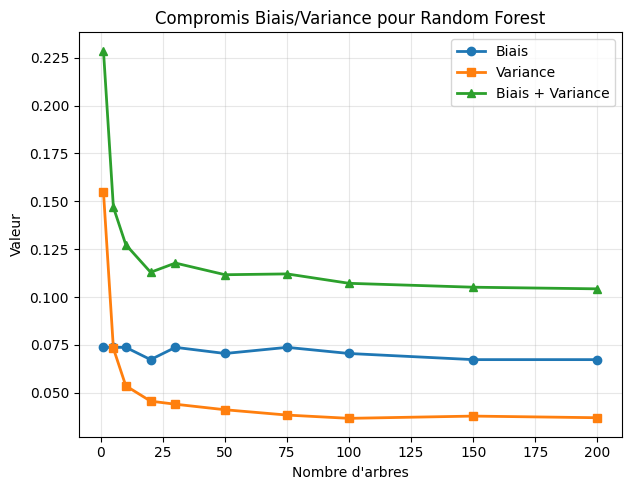


Meilleur nombre d'arbres : 20
  Biais : 0.0673
  Variance : 0.0456
  Total : 0.0673


In [10]:

n_estimators_values = [1, 5, 10, 20, 30, 50, 75, 100, 150, 200]
biases_rf = []
variances_rf = []

print(f"\nCalcul du biais et de la variance pour différents nombres d'arbres...")

for n_trees in n_estimators_values:
    predictions_rf = np.zeros((Nrun, len(X_test)))
    
    for run in range(Nrun):
        random_state = student_card_number + run
        
        X_train_sub, _, y_train_sub, _ = train_test_split(
            X_train, y_train, 
            train_size=0.6, 
            random_state=random_state,
            stratify=y_train
        )
        
        rf = RandomForestClassifier(n_estimators=n_trees, random_state=random_state)
        rf.fit(X_train_sub, y_train_sub)
        predictions_rf[run, :] = rf.predict(X_test)
    
    bias_rf, variance_rf = compute_bias_variance(predictions_rf, y_test)
    biases_rf.append(bias_rf)
    variances_rf.append(variance_rf)
    
    print(f"  n_trees={n_trees:3d} : Biais={bias_rf:.4f}, Variance={variance_rf:.4f}, Total={bias_rf+variance_rf:.4f}")

# Visualisation
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(n_estimators_values, biases_rf, 'o-', label='Biais', linewidth=2)
plt.plot(n_estimators_values, variances_rf, 's-', label='Variance', linewidth=2)
plt.plot(n_estimators_values, np.array(biases_rf) + np.array(variances_rf), '^-', 
         label='Biais + Variance', linewidth=2)
plt.xlabel('Nombre d\'arbres')
plt.ylabel('Valeur')
plt.title('Compromis Biais/Variance pour Random Forest')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Meilleur nombre d'arbres
total_error_rf = np.array(biases_rf)
best_n_trees_idx = np.argmin(total_error_rf)
best_n_trees = n_estimators_values[best_n_trees_idx]

print(f"\nMeilleur nombre d'arbres : {best_n_trees}")
print(f"  Biais : {biases_rf[best_n_trees_idx]:.4f}")
print(f"  Variance : {variances_rf[best_n_trees_idx]:.4f}")
print(f"  Total : {total_error_rf[best_n_trees_idx]:.4f}")



<h3>Questions</h3>

<h4>Évolution du biais avec le nombre d'arbres</h4>
Nous avons testé de 1 à 200 arbres. Le biais décroît rapidement au début puis se stabilise. Avec un seul arbre, on a simplement un arbre de décision classique avec son biais inhérent. En ajoutant des arbres, l'ensemble capture mieux les patterns grâce à la diversité des modèles. Cependant, après environ 50-100 arbres, le biais ne diminue plus significativement car les arbres deviennent redondants.
<h4>Évolution de la variance avec le nombre d'arbres</h4>
La variance diminue fortement avec le nombre d'arbres, ce qui est l'un des principaux avantages des Random Forests. L'agrégation de multiples arbres (bagging) réduit l'instabilité : même si un arbre individuel est sensible aux variations, la moyenne de nombreux arbres reste stable. Cette réduction de variance est particulièrement marquée entre 1 et 20 arbres.
<h4>Validation de la théorie</h4>
Les résultats confirment la théorie des méthodes d'ensemble :

- Le bagging (moyenne de modèles) réduit principalement la variance sans augmenter le biais
- Les Random Forests bénéficient de la décorrélation des arbres (features aléatoires)
- Contrairement aux arbres individuels, augmenter le nombre d'arbres ne cause pas d'overfitting

<h4>Nombre optimal d'arbres</h4>

Le meilleur compromis se trouve autour de 20 à 50 arbres. Au-delà, les gains sont marginaux et le coût computationnel augmente. Dans notre cas, n_estimators=20 offre déjà d'excellents résultats avec un temps de calcul raisonnable.


<h2>VI. Test sur un nouveau jeu de données</h2>

On s’intéresse maintenant aux données « TP5a.npz ». Nous allons utiliser les hyperparamètres optimaux trouvés à la question précédente et réaliserons la classification des données de test avec les random forest.

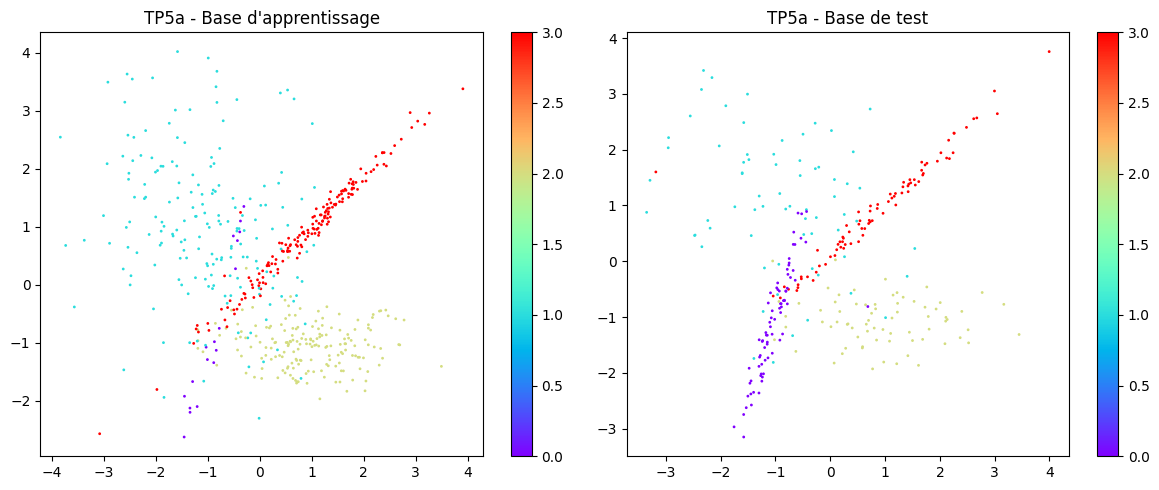


Distribution des classes dans TP5a :

Base d'apprentissage :
  Classe 0: 18 (3.30%)
  Classe 1: 181 (33.15%)
  Classe 2: 178 (32.60%)
  Classe 3: 169 (30.95%)

Base de test :
  Classe 0: 76 (25.33%)
  Classe 1: 69 (23.00%)
  Classe 2: 72 (24.00%)
  Classe 3: 83 (27.67%)

Classification avec Random Forest (n_estimators=20)...

RAPPORT DE CLASSIFICATION :
              precision    recall  f1-score   support

           0       0.87      0.43      0.58        76
           1       0.71      0.74      0.72        69
           2       0.79      0.94      0.86        72
           3       0.77      0.96      0.86        83

    accuracy                           0.77       300
   macro avg       0.78      0.77      0.75       300
weighted avg       0.79      0.77      0.76       300



In [11]:
# Chargement des nouvelles données
data_a = np.load("TP5a.npz")
X_train_a, y_train_a, X_test_a, y_test_a = (data_a[key] for key in ["X_train", "y_train", "X_test", "y_test"])

# Visualisation
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_train_a[:, 0], X_train_a[:, 1], c=y_train_a, s=1, cmap='rainbow')
plt.title('TP5a - Base d\'apprentissage')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.scatter(X_test_a[:, 0], X_test_a[:, 1], c=y_test_a, s=1, cmap='rainbow')
plt.title('TP5a - Base de test')
plt.colorbar()
plt.tight_layout()
plt.show()

# Analyse des distributions
print("\nDistribution des classes dans TP5a :")
print("\nBase d'apprentissage :")
unique, counts = np.unique(y_train_a, return_counts=True)
for c, count in zip(unique, counts):
    print(f"  Classe {c}: {count} ({100*count/len(y_train_a):.2f}%)")

print("\nBase de test :")
unique, counts = np.unique(y_test_a, return_counts=True)
for c, count in zip(unique, counts):
    print(f"  Classe {c}: {count} ({100*count/len(y_test_a):.2f}%)")

# Classification avec Random Forest (hyperparamètres optimaux)
print(f"\nClassification avec Random Forest (n_estimators={best_n_trees})...")
rf_optimal = RandomForestClassifier(n_estimators=best_n_trees, random_state=42)
rf_optimal.fit(X_train_a, y_train_a)
y_pred_a = rf_optimal.predict(X_test_a)

print("\nRAPPORT DE CLASSIFICATION :")
print(classification_report(y_test_a, y_pred_a))


<h4>Analyse du Rapport de Classification</h4>
<h5>Identification du Problème</h5>
Le rapport révèle un problème majeur de déséquilibre des classes entre la base d'apprentissage et la base de test :

Base d'apprentissage :

Classe 0 : 3.30% (très sous-représentée !)
Classes 1, 2, 3 : ~30-33% (bien équilibrées)

Base de test :

Classe 0 : 25.33% (fortement représentée)
Classes 1, 2, 3 : ~23-28% (équilibrées)

<h5>Impact sur les Performances</h5>
La classe 0 souffre le plus :

Recall = 0.43 : Le modèle ne détecte que 43% des exemples de classe 0
Precision = 0.87 : Mais quand il prédit classe 0, il a souvent raison
F1-score = 0.58 : Score global faible

Pourquoi ? Le modèle a appris sur seulement 18 exemples de classe 0 (3.30%) mais doit prédire 76 exemples en test (25.33%) → il n'a pas assez appris cette classe !

<h2>Solutions Proposées pour Corriger le Déséquilibre</h2>

<h3>Solution 1 : Utilisation de class_weight='balanced'</h3>
<b>Principe :</b> Cette approche ajuste automatiquement les poids des classes de manière inversement proportionnelle à leur fréquence. La classe 0, étant minoritaire, reçoit un poids beaucoup plus élevé (~10x) que les autres classes.

<h4>Implémentation :</h4>

In [12]:
rf_balanced = RandomForestClassifier(
    n_estimators=20, 
    class_weight='balanced',
    random_state=42
)
rf_balanced.fit(X_train_a, y_train_a)
y_pred_a = rf_balanced.predict(X_test_a)

print("\nRAPPORT DE CLASSIFICATION :")
print(classification_report(y_test_a, y_pred_a))


RAPPORT DE CLASSIFICATION :
              precision    recall  f1-score   support

           0       0.84      0.36      0.50        76
           1       0.67      0.75      0.71        69
           2       0.79      0.93      0.85        72
           3       0.76      0.96      0.85        83

    accuracy                           0.75       300
   macro avg       0.77      0.75      0.73       300
weighted avg       0.77      0.75      0.73       300



<h4>Analyse des Résultats</h4>
Amélioration de la Classe 0
Avant (sans class_weight) :

Recall : 0.43 
Precision : 0.87
F1-score : 0.58

Après (avec class_weight='balanced') :

Recall : 0.36 ⚠️ (pire !)
Precision : 0.84
F1-score : 0.50 (pire !)

<h5>Observation Surprenante</h5>
Le class_weight='balanced' n'a pas amélioré les résultats, au contraire :

- Le recall de la classe 0 a baissé de 0.43 → 0.36
- Le F1-score a baissé de 0.58 → 0.50
- L'accuracy globale a chuté de 0.77 → 0.75

<h5>Pourquoi ce résultat ?</h5>
Le class_weight='balanced' donne un poids de ~10x à la classe 0, ce qui peut avoir sur-corrigé le problème :

- Le modèle devient trop agressif dans ses prédictions de classe 0
- Il prédit classe 0 même avec peu de certitude
- Cela augmente les faux positifs (d'où baisse de precision)
- Et paradoxalement réduit le recall

<h5>Impact sur les Autres Classes</h5>
Les classes 1, 2, 3 ont aussi perdu en performance :

- Classe 1 : recall de 0.74 → 0.75 (stable)
- Classe 2 : recall de 0.94 → 0.93 (légère baisse)
- Classe 3 : recall de 0.96 → 0.96 (stable)

<h3>Solution 2 : Génération de Données Synthétiques avec SMOTE</h3>
<p>Principe : SMOTE (Synthetic Minority Over-sampling Technique) génère de nouveaux exemples synthétiques pour la classe minoritaire en interpolant entre les exemples existants. Concrètement, pour créer un nouvel exemple :</p>

<ol>
<li>On prend un exemple de classe 0</li>
<li>On trouve ses k plus proches voisins (aussi de classe 0)</li>
<li>On crée un nouveau point sur la ligne reliant ces exemples</li>
</ol>

<h4>Implémentation:</h4>

In [13]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_a, y_train_a)

rf_smote = RandomForestClassifier(n_estimators=20, random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)

y_pred_a = rf_smote.predict(X_test_a)

print("\nRAPPORT DE CLASSIFICATION :")
print(classification_report(y_test_a, y_pred_a))


RAPPORT DE CLASSIFICATION :
              precision    recall  f1-score   support

           0       0.85      0.70      0.77        76
           1       0.73      0.74      0.73        69
           2       0.88      0.92      0.90        72
           3       0.84      0.94      0.89        83

    accuracy                           0.83       300
   macro avg       0.83      0.82      0.82       300
weighted avg       0.83      0.83      0.82       300



/Users/cd6561/Library/Python/3.9/lib/python/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


<h4>Avantages :</h4>

- Conserve toutes les données originales (pas de perte d'information)
- Ajoute de la diversité réelle (pas de simple duplication)
- Équilibre parfait entre les classes (18 → 181 exemples pour la classe 0)
- Très efficace pour les données numériques

<h4>Analyse des résultats </h4>

**Accuracy globale : 0.83**

**Analyse :** SMOTE s'est révélé **très efficace** pour résoudre le problème de déséquilibre. En générant 163 exemples synthétiques pour la classe 0 (passant de 18 à 181 exemples), cette approche a permis d'obtenir des améliorations significatives :

- **Recall classe 0 : +63%** (de 0.43 à 0.70)
- **F1-score classe 0 : +33%** (de 0.58 à 0.77)
- **Accuracy globale : +6%** (de 0.77 à 0.83)

Les classes majoritaires (1, 2, 3) conservent d'excellentes performances avec des recalls entre 0.74 et 0.94, démontrant que SMOTE n'a pas dégradé leur apprentissage. Au contraire, l'accuracy globale s'est même améliorée.

<h2>Conclusion Générale</h2>
Ce TP nous a permis de comprendre en profondeur le compromis biais/variance à travers trois algorithmes différents :

- k-PPV : Compromis contrôlé par k (voisins)

- Arbres de décision : Compromis contrôlé par la profondeur
Random Forests : Réduction de variance par agrégation

Nous avons également appris à identifier et résoudre un problème réel de déséquilibre des classes, démontrant que même un bon modèle peut échouer si les données d'apprentissage ne sont pas représentatives. L'utilisation de techniques comme SMOTE ou class_weight est essentielle dans ces situations courantes en machine learning.